# Lula × Bolsonaro: o que os leitos hospitalares mostram (2019–2026)

Série de **Hospitais e Leitos** (Dados Abertos do SUS), competência de referência em junho de cada ano. Os períodos 2019–2022 e 2023–2026 entram como **marcadores temporais** — não como prova de causalidade federal isolada (estados, municípios, pandemia e cadastro CNES pesam).

Quatro leituras: placar de estoque, desigualdade regional, oferta per capita e vínculo real com o SUS.


## Dados


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path("..").resolve()
if not (ROOT / "data" / "processed").exists():
    ROOT = Path(".").resolve()

PROCESSED = ROOT / "data" / "processed"
EXTERNAL = ROOT / "data" / "external"
FIG = ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.axisbelow"] = True

print("ROOT =", ROOT)


ROOT = C:\Users\luiso\OneDrive\Documentos\Análise de Dados - SUS


In [2]:
def load_leitos(mes_ref: str = "06") -> pd.DataFrame:
    """Carrega série processada e filtra uma competência mensal por ano (estoque)."""
    frames = []
    for path in sorted(PROCESSED.glob("leitos_*.csv")):
        df = pd.read_csv(
            path,
            sep=";",
            dtype={"COMP": str, "ANO": str, "MES": str, "CNES": str, "UF": str},
        )
        frames.append(df)
    raw = pd.concat(frames, ignore_index=True)

    snap = raw[raw["MES"] == mes_ref].copy()
    anos_sem_mes = set(raw["ANO"].unique()) - set(snap["ANO"].unique())
    if anos_sem_mes:
        comps = [raw.loc[raw["ANO"] == ano, "COMP"].min() for ano in anos_sem_mes]
        snap = pd.concat([snap, raw[raw["COMP"].isin(comps)]], ignore_index=True)

    snap["ANO_INT"] = snap["ANO"].astype(int)
    snap["LEITOS_NAO_SUS"] = (snap["LEITOS_EXISTENTES"] - snap["LEITOS_SUS"]).clip(lower=0)
    return snap


def load_populacao() -> pd.DataFrame:
    pop = pd.read_csv(EXTERNAL / "populacao_uf_ibge.csv", sep=";")
    pop["ANO"] = pop["ANO"].astype(int)
    return pop


def pop_para_ano(pop: pd.DataFrame, ano: int) -> pd.DataFrame:
    """Usa o ano exato ou o mais próximo disponível (2020-2024)."""
    anos = sorted(pop["ANO"].unique())
    alvo = min(anos, key=lambda a: abs(a - ano))
    out = pop[pop["ANO"] == alvo][["UF", "REGIAO", "POPULACAO"]].copy()
    out["ANO_POP"] = alvo
    out["ANO_LEITOS"] = ano
    return out


leitos = load_leitos("06")
pop = load_populacao()

print("Linhas no snapshot (1 competencia/ano):", f"{len(leitos):,}".replace(",", "."))
print("Anos:", sorted(leitos["ANO_INT"].unique()))
print("Competencias usadas por ano:")
print(leitos.groupby("ANO")["COMP"].first().to_string())


Linhas no snapshot (1 competencia/ano): 142.928
Anos: [np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]
Competencias usadas por ano:
ANO
2007    200707
2008    200806
2009    200906
2010    201006
2011    201106
2012    201206
2013    201306
2014    201406
2015    201506
2016    201606
2017    201706
2018    201806
2019    201906
2020    202006
2021    202106
2022    202206
2023    202306
2024    202406
2025    202506
2026    202606


## Panorama nacional


In [3]:
nacional = (
    leitos.groupby("ANO_INT", as_index=False)
    .agg(
        leitos_existentes=("LEITOS_EXISTENTES", "sum"),
        leitos_sus=("LEITOS_SUS", "sum"),
        leitos_nao_sus=("LEITOS_NAO_SUS", "sum"),
        uti_sus=("UTI_TOTAL_SUS", "sum"),
        estabelecimentos=("CNES", "nunique"),
    )
)
nacional["taxa_sus"] = nacional["leitos_sus"] / nacional["leitos_existentes"]
nacional["periodo"] = np.select(
    [
        nacional["ANO_INT"].between(2019, 2022),
        nacional["ANO_INT"].between(2023, 2026),
    ],
    ["Bolsonaro (2019-2022)", "Lula (2023-2026)"],
    default="Fora do recorte",
)

uf_ano = (
    leitos.groupby(["ANO_INT", "UF", "REGIAO"], as_index=False)
    .agg(
        leitos_existentes=("LEITOS_EXISTENTES", "sum"),
        leitos_sus=("LEITOS_SUS", "sum"),
        leitos_nao_sus=("LEITOS_NAO_SUS", "sum"),
        uti_sus=("UTI_TOTAL_SUS", "sum"),
    )
)

# UFs tipicamente lidas como "centro economico" na provocacao de desigualdade
UF_CENTRO = {"SP", "RJ", "MG", "DF", "PR", "RS", "SC"}

nacional


,ANO_INT,leitos_existentes,leitos_sus,leitos_nao_sus,uti_sus,estabelecimentos,taxa_sus,periodo
0,2007,478626,358306,120320,3513,7400,0.748614,Fora do recorte
1,2008,490823,350526,140297,2856,7363,0.714160,Fora do recorte
2,2009,499624,361510,138114,14712,7435,0.723564,Fora do recorte
3,2010,499670,358896,140774,15818,7422,0.718266,Fora do recorte
4,2011,499478,355477,144001,16688,7333,0.711697,Fora do recorte
5,2012,497583,352499,145084,17894,7266,0.708423,Fora do recorte
6,2013,497945,347116,150829,18906,7180,0.697097,Fora do recorte
7,2014,497798,344993,152805,19419,7173,0.693038,Fora do recorte
8,2015,485922,338156,147766,19799,6962,0.695906,Fora do recorte
9,2016,480844,332804,148040,20204,6911,0.692125,Fora do recorte


## 1. Em qual governo o estoque cresceu mais?

No placar frio de **leitos SUS** (jun/2019 → jun/2022 vs jun/2023 → jun/2025):

| Período | Início | Fim | Variação | % |
|---|---:|---:|---:|---:|
| Bolsonaro (2019→2022) | 323.361 | 345.095 | **+21.734** | **+6,72%** |
| Lula (2023→2025) | 343.672 | 351.776 | +8.104 | +2,36% |

Em **leitos existentes**, a mesma lógica: +6,43% no primeiro intervalo e +2,43% no segundo. Em **UTI SUS**, o contraste é maior (+36,9% vs +3,9%) — mas isso coincide com a expansão (e depois acomodação) da pandemia.

**Leitura:** o período Bolsonaro “ganha” o placar percentual de estoque. A leitura adulta exige lembrar o pico de 2020–2021 e a queda parcial em 2022: sem COVID, o placar muda de figura.


In [4]:
def variacao(df, ano_ini, ano_fim, col="leitos_existentes"):
    a = df.loc[df["ANO_INT"] == ano_ini, col].iloc[0]
    b = df.loc[df["ANO_INT"] == ano_fim, col].iloc[0]
    return {
        "inicio": int(ano_ini),
        "fim": int(ano_fim),
        "valor_inicio": int(a),
        "valor_fim": int(b),
        "var_abs": int(b - a),
        "var_pct": round((b - a) / a * 100, 2) if a else np.nan,
    }


metricas = ["leitos_existentes", "leitos_sus", "uti_sus"]
linhas = []
for col in metricas:
    bol = variacao(nacional, 2019, 2022, col)
    bol["governo"] = "Bolsonaro (2019→2022)"
    bol["metrica"] = col
    lula = variacao(nacional, 2023, 2025, col)
    lula["governo"] = "Lula (2023→2025)"
    lula["metrica"] = col
    linhas.extend([bol, lula])
    if 2026 in set(nacional["ANO_INT"]):
        lula26 = variacao(nacional, 2023, 2026, col)
        lula26["governo"] = "Lula (2023→2026 parcial)"
        lula26["metrica"] = col
        linhas.append(lula26)

cmp = pd.DataFrame(linhas)
print("=== Placar provocativo (olhe sobretudo leitos_sus e uti_sus) ===")
cmp[["governo", "metrica", "valor_inicio", "valor_fim", "var_abs", "var_pct"]]


=== Placar provocativo (olhe sobretudo leitos_sus e uti_sus) ===


,governo,metrica,valor_inicio,valor_fim,var_abs,var_pct
0,Bolsonaro (2019→2022),leitos_existentes,478128,508871,30743,6.43
1,Lula (2023→2025),leitos_existentes,508713,521093,12380,2.43
2,Lula (2023→2026 parcial),leitos_existentes,508713,523082,14369,2.82
3,Bolsonaro (2019→2022),leitos_sus,323361,345095,21734,6.72
4,Lula (2023→2025),leitos_sus,343672,351776,8104,2.36
5,Lula (2023→2026 parcial),leitos_sus,343672,354343,10671,3.10
6,Bolsonaro (2019→2022),uti_sus,22141,30300,8159,36.85
7,Lula (2023→2025),uti_sus,30867,32076,1209,3.92
8,Lula (2023→2026 parcial),uti_sus,30867,32125,1258,4.08


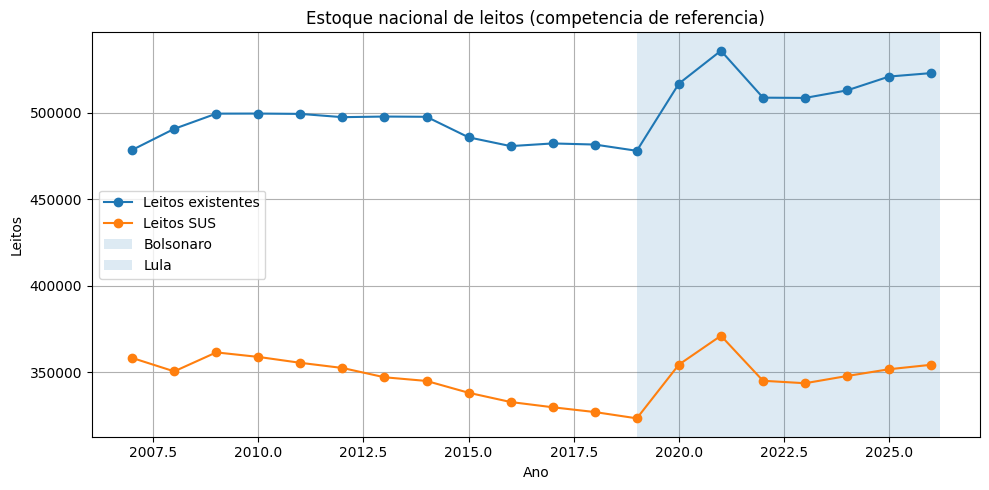


PROVOCACAO: Em leitos SUS (2019→2022 vs 2023→2025), a variacao percentual foi
  Bolsonaro: 6.72% (+21734 leitos)
  Lula:      2.36% (+8104 leitos)
Leitura de hype: "ganhou" em variacao % → Bolsonaro.
Leitura adulta: compare tambem UTI, pandemia (2020-21) e o fato de 2026 ainda estar aberto.



In [5]:
fig, ax = plt.subplots()
ax.plot(nacional["ANO_INT"], nacional["leitos_existentes"], marker="o", label="Leitos existentes")
ax.plot(nacional["ANO_INT"], nacional["leitos_sus"], marker="o", label="Leitos SUS")
ax.axvspan(2019, 2022.5, alpha=0.15, label="Bolsonaro")
ax.axvspan(2022.5, 2026.2, alpha=0.15, label="Lula")
ax.set_title("Estoque nacional de leitos (competencia de referencia)")
ax.set_xlabel("Ano")
ax.set_ylabel("Leitos")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "01_serie_nacional_leitos.png", dpi=140)
plt.show()

focus = cmp[cmp["metrica"] == "leitos_sus"]
b = focus[focus["governo"].str.startswith("Bolsonaro")].iloc[0]
l = focus[focus["governo"] == "Lula (2023→2025)"].iloc[0]
vencedor = "Bolsonaro" if b["var_pct"] > l["var_pct"] else "Lula"
print(
    f"""
PROVOCACAO: Em leitos SUS (2019→2022 vs 2023→2025), a variacao percentual foi
  Bolsonaro: {b['var_pct']}% ({b['var_abs']:+d} leitos)
  Lula:      {l['var_pct']}% ({l['var_abs']:+d} leitos)
Leitura de hype: "ganhou" em variacao % → {vencedor}.
Leitura adulta: compare tambem UTI, pandemia (2020-21) e o fato de 2026 ainda estar aberto.
"""
)


O gráfico deixa o choque pandêmico visível: salto em 2020–2021 e reacomodação em 2022, antes da trajetória mais estável/ascendente sob Lula. O número cheio do mandato anterior não é “entrega linear” — é série com quebra estrutural no meio.


## 2. O Brasil ganhou leitos — e ficou mais desigual?

Hipótese de hype: o crescimento se concentra em SP, RJ, MG, DF e Sul. Os dados apontam **o contrário no recorte recente**.

Participação dos leitos SUS:

| Ano | Centro econômico* | Top-5 UFs | Norte + Nordeste |
|---|---:|---:|---:|
| 2019 | 53,54% | 49,36% | 38,20% |
| 2022 | 52,07% | 48,58% | 39,34% |
| 2025 | 51,83% | 48,01% | 39,29% |

\*SP, RJ, MG, DF, PR, RS, SC

- Bolsonaro 2019→2022: centro **−1,47 p.p.**; Norte+Nordeste **+1,14 p.p.**
- Lula 2023→2025: centro **−0,09 p.p.**; Norte+Nordeste **+0,03 p.p.** (quase estável)

**Leitura:** entre 2019 e 2022 a distribuição ficou um pouco **menos** concentrada no “centro”. De 2023 a 2025, a geografia do estoque quase não se move. Ganhar leitos no Brasil recente **não** veio, neste indicador, acompanhado de um avanço claro da desigualdade espacial — o plot twist é esse.


In [6]:
def concentracao(ano_df: pd.DataFrame, col="leitos_sus") -> dict:
    total = ano_df[col].sum()
    centro = ano_df.loc[ano_df["UF"].isin(UF_CENTRO), col].sum()
    top5 = ano_df.nlargest(5, col)[col].sum()
    nn = ano_df.loc[ano_df["REGIAO"].isin(["NORTE", "NORDESTE"]), col].sum()
    ss = ano_df.loc[ano_df["REGIAO"].isin(["SUDESTE", "SUL"]), col].sum()
    return {
        "total": total,
        "share_centro": centro / total if total else np.nan,
        "share_top5": top5 / total if total else np.nan,
        "share_norte_nordeste": nn / total if total else np.nan,
        "share_sudeste_sul": ss / total if total else np.nan,
    }


rows = []
for ano, g in uf_ano.groupby("ANO_INT"):
    if ano < 2015:
        continue
    r = concentracao(g, "leitos_sus")
    r["ANO"] = ano
    r["periodo"] = (
        "Bolsonaro" if 2019 <= ano <= 2022 else "Lula" if ano >= 2023 else "Pre"
    )
    rows.append(r)

conc = pd.DataFrame(rows).sort_values("ANO")
conc["share_centro_pct"] = (conc["share_centro"] * 100).round(2)
conc["share_top5_pct"] = (conc["share_top5"] * 100).round(2)
conc["share_nn_pct"] = (conc["share_norte_nordeste"] * 100).round(2)
conc[["ANO", "periodo", "share_centro_pct", "share_top5_pct", "share_nn_pct", "total"]]


,ANO,periodo,share_centro_pct,share_top5_pct,share_nn_pct,total
0,2015,Pre,54.85,50.86,37.01,338156
1,2016,Pre,54.28,50.29,37.62,332804
2,2017,Pre,53.90,49.89,37.85,329768
3,2018,Pre,53.70,49.60,38.09,327003
4,2019,Bolsonaro,53.54,49.36,38.20,323361
5,2020,Bolsonaro,53.09,49.28,38.89,354440
6,2021,Bolsonaro,52.86,48.91,38.62,371142
7,2022,Bolsonaro,52.07,48.58,39.34,345095
8,2023,Lula,51.92,48.44,39.26,343672
9,2024,Lula,52.08,48.33,39.04,347861


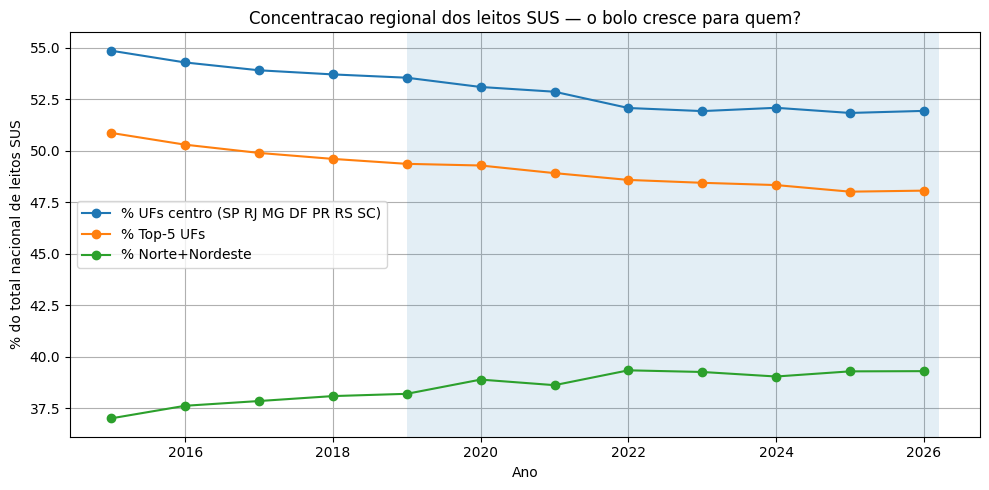

Variacao do share do CENTRO (p.p.):
  Bolsonaro 2019→2022: -1.47 p.p.
  Lula 2023→2025:      -0.09 p.p.
Variacao do share Norte+Nordeste (p.p.):
  Bolsonaro 2019→2022: +1.14 p.p.
  Lula 2023→2025:      +0.03 p.p.

PROVOCACAO: Se o share do centro sobe enquanto o total nacional tambem sobe,
o pais "ganha leitos" e, ao mesmo tempo, pode estar reforcando desigualdade espacial.
Se o Norte+Nordeste ganha share, a narrativa inverte — e isso tambem e noticia.



In [7]:
fig, ax = plt.subplots()
ax.plot(conc["ANO"], conc["share_centro_pct"], marker="o", label="% UFs centro (SP RJ MG DF PR RS SC)")
ax.plot(conc["ANO"], conc["share_top5_pct"], marker="o", label="% Top-5 UFs")
ax.plot(conc["ANO"], conc["share_nn_pct"], marker="o", label="% Norte+Nordeste")
ax.axvspan(2019, 2022.5, alpha=0.12)
ax.axvspan(2022.5, 2026.2, alpha=0.12)
ax.set_title("Concentracao regional dos leitos SUS — o bolo cresce para quem?")
ax.set_ylabel("% do total nacional de leitos SUS")
ax.set_xlabel("Ano")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "02_concentracao_regional.png", dpi=140)
plt.show()


def delta_share(col, a0, a1):
    s0 = conc.loc[conc["ANO"] == a0, col].iloc[0]
    s1 = conc.loc[conc["ANO"] == a1, col].iloc[0]
    return s1 - s0


print("Variacao do share do CENTRO (p.p.):")
print(f"  Bolsonaro 2019→2022: {delta_share('share_centro_pct', 2019, 2022):+.2f} p.p.")
print(f"  Lula 2023→2025:      {delta_share('share_centro_pct', 2023, 2025):+.2f} p.p.")
print("Variacao do share Norte+Nordeste (p.p.):")
print(f"  Bolsonaro 2019→2022: {delta_share('share_nn_pct', 2019, 2022):+.2f} p.p.")
print(f"  Lula 2023→2025:      {delta_share('share_nn_pct', 2023, 2025):+.2f} p.p.")
print(
    """
PROVOCACAO: Se o share do centro sobe enquanto o total nacional tambem sobe,
o pais "ganha leitos" e, ao mesmo tempo, pode estar reforcando desigualdade espacial.
Se o Norte+Nordeste ganha share, a narrativa inverte — e isso tambem e noticia.
"""
)


## 3. Gigante no absoluto, frágil no per capita

Volume total engana. Em 2025, **SP** lidera leitos SUS absolutos (61.684), mas cai para a **26ª** posição em leitos SUS por 1.000 habitantes (~1,34). **RJ** é 4º no absoluto e 25º no per capita; **MG** é 2º e 21º.

Quem “despenca” do ranking de volume para o de oferta relativa: SP, RJ, MG, BA, PA, PR, SC, GO.

Enquanto isso, a média per capita do Norte+Nordeste (2019/2022/2025) fica **acima** da média do bloco centro — outro contraponto ao senso comum “estado rico = população bem coberta”.

**Leitura:** o debate Lula × Bolsonaro sobre “quantos leitos o Brasil tem” ignora o teste constrangedor: **por habitante**, vários estados ricos parecem bem menos generosos do que o ranking absoluto sugere.


In [8]:
anos_foco = [2019, 2022, 2025]
anos_disp = set(uf_ano["ANO_INT"])
anos_foco = [a for a in anos_foco if a in anos_disp]
if 2025 not in anos_foco and any(a >= 2023 for a in anos_disp):
    anos_foco.append(max(a for a in anos_disp if a >= 2023))
anos_foco = sorted(set(anos_foco))

frames = []
for ano in anos_foco:
    base = uf_ano[uf_ano["ANO_INT"] == ano].copy()
    p = pop_para_ano(pop, ano)
    m = base.merge(p, on=["UF", "REGIAO"], how="left")
    m["leitos_sus_abs"] = m["leitos_sus"]
    m["leitos_sus_per_1000"] = m["leitos_sus"] / m["POPULACAO"] * 1000
    m["leitos_exist_per_1000"] = m["leitos_existentes"] / m["POPULACAO"] * 1000
    frames.append(m)

pc = pd.concat(frames, ignore_index=True)

ano_ref = max(anos_foco)
ref = pc[pc["ANO_INT"] == ano_ref].copy()
ref["rank_abs"] = ref["leitos_sus_abs"].rank(ascending=False, method="min")
ref["rank_pc"] = ref["leitos_sus_per_1000"].rank(ascending=False, method="min")
ref["gap_rank"] = ref["rank_pc"] - ref["rank_abs"]

print(f"Ano de referencia per capita: {ano_ref} (pop IBGE ~{int(ref['ANO_POP'].iloc[0])})")
print("\nTop 8 em leitos SUS ABSOLUTOS:")
print(
    ref.nlargest(8, "leitos_sus_abs")[
        ["UF", "leitos_sus_abs", "leitos_sus_per_1000", "rank_abs", "rank_pc"]
    ].to_string(index=False)
)
print("\nUFs que mais despencam do ranking absoluto para o per capita:")
print(
    ref.nlargest(8, "gap_rank")[
        ["UF", "leitos_sus_abs", "leitos_sus_per_1000", "rank_abs", "rank_pc", "gap_rank"]
    ].to_string(index=False)
)


Ano de referencia per capita: 2025 (pop IBGE ~2024)

Top 8 em leitos SUS ABSOLUTOS:
UF  leitos_sus_abs  leitos_sus_per_1000  rank_abs  rank_pc
SP           61684             1.341738       1.0     26.0
MG           33327             1.562983       2.0     21.0
BA           27009             1.818725       3.0     16.0
RJ           24002             1.393870       4.0     25.0
RS           22861             2.035723       5.0      3.0
PR           21647             1.830665       6.0     15.0
PE           18061             1.893379       7.0      8.0
CE           17374             1.881595       8.0     11.0

UFs que mais despencam do ranking absoluto para o per capita:
UF  leitos_sus_abs  leitos_sus_per_1000  rank_abs  rank_pc  gap_rank
SP           61684             1.341738       1.0     26.0      25.0
RJ           24002             1.393870       4.0     25.0      21.0
MG           33327             1.562983       2.0     21.0      19.0
BA           27009             1.818725       

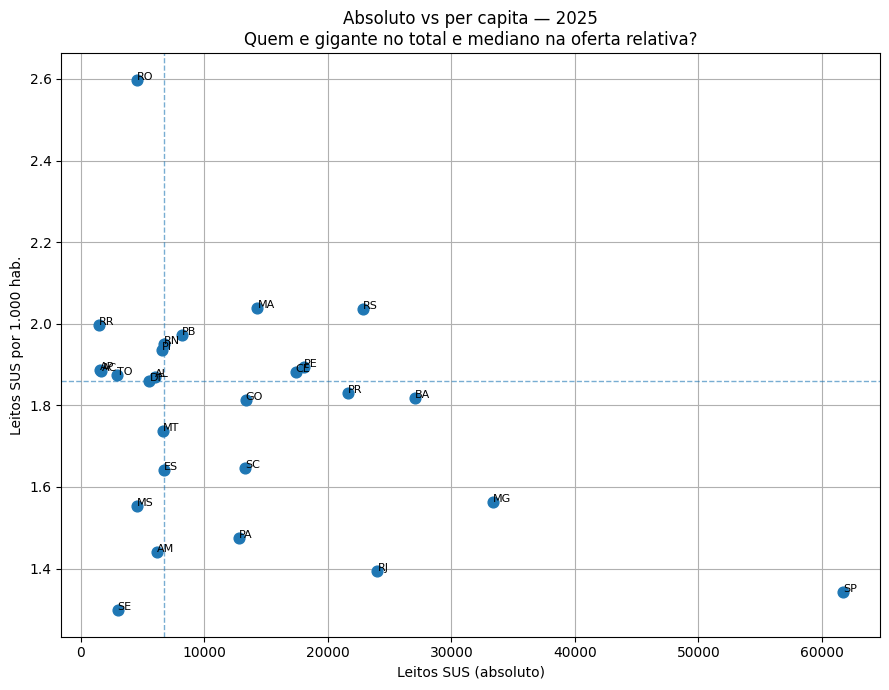

2019: centro=1.576 | N+NE=1.613
2022: centro=1.686 | N+NE=1.894
2025: centro=1.667 | N+NE=1.863

PROVOCACAO: Se SP/RJ lideram o absoluto mas caem no per capita, o discurso
"estado rico = populacao bem servida" nao se sustenta so com ranking de volume.
Compare 2019 (inicio Bolsonaro) vs 2025 (Lula) nas medias centro x Norte/Nordeste.



In [9]:
fig, ax = plt.subplots(figsize=(9, 7))
r = pc[pc["ANO_INT"] == ano_ref]
ax.scatter(r["leitos_sus_abs"], r["leitos_sus_per_1000"], s=60)
for _, row in r.iterrows():
    ax.annotate(row["UF"], (row["leitos_sus_abs"], row["leitos_sus_per_1000"]), fontsize=8)
ax.set_xlabel("Leitos SUS (absoluto)")
ax.set_ylabel("Leitos SUS por 1.000 hab.")
ax.set_title(
    f"Absoluto vs per capita — {ano_ref}\nQuem e gigante no total e mediano na oferta relativa?"
)
ax.axvline(r["leitos_sus_abs"].median(), ls="--", lw=1, alpha=0.6)
ax.axhline(r["leitos_sus_per_1000"].median(), ls="--", lw=1, alpha=0.6)
fig.tight_layout()
fig.savefig(FIG / "03_absoluto_vs_per_capita.png", dpi=140)
plt.show()


def media_pc(ano, ufs=None, regioes=None):
    d = pc[pc["ANO_INT"] == ano]
    if ufs is not None:
        d = d[d["UF"].isin(ufs)]
    if regioes is not None:
        d = d[d["REGIAO"].isin(regioes)]
    return d["leitos_sus_per_1000"].mean()


for ano in anos_foco:
    c = media_pc(ano, ufs=UF_CENTRO)
    n = media_pc(ano, regioes=["NORTE", "NORDESTE"])
    print(f"{ano}: centro={c:.3f} | N+NE={n:.3f}")

print(
    """
PROVOCACAO: Se SP/RJ lideram o absoluto mas caem no per capita, o discurso
"estado rico = populacao bem servida" nao se sustenta so com ranking de volume.
Compare 2019 (inicio Bolsonaro) vs 2025 (Lula) nas medias centro x Norte/Nordeste.
"""
)


## 4. Mais leitos = mais SUS?

Nem sempre. A taxa leitos SUS / leitos existentes ficou praticamente **estável**:

| Período | Taxa SUS início → fim | Δ |
|---|---|---|
| Bolsonaro 2019→2022 | 67,63% → 67,82% | **+0,19 p.p.** |
| Lula 2023→2025 | 67,56% → 67,51% | **−0,05 p.p.** |

Leitos **não SUS** (existentes − SUS) também cresceram nos dois intervalos (+9.009 e +4.276). Ou seja: o estoque total sobe, mas a **fatia vinculada ao SUS** não acompanha um salto estrutural em nenhum dos dois governos.

**Leitura:** dá para “ganhar leitos” no CNES sem transformar o acesso. No hype político, o número cheio vende; o indicador que importa para o SUS é a composição.


In [10]:
decomp = nacional[nacional["ANO_INT"] >= 2015][
    ["ANO_INT", "leitos_existentes", "leitos_sus", "leitos_nao_sus", "taxa_sus", "periodo"]
].copy()
decomp["taxa_sus_pct"] = (decomp["taxa_sus"] * 100).round(2)
decomp


,ANO_INT,leitos_existentes,leitos_sus,leitos_nao_sus,taxa_sus,periodo,taxa_sus_pct
8,2015,485922,338156,147766,0.695906,Fora do recorte,69.59
9,2016,480844,332804,148040,0.692125,Fora do recorte,69.21
10,2017,482390,329768,152622,0.683613,Fora do recorte,68.36
11,2018,481746,327003,154743,0.678787,Fora do recorte,67.88
12,2019,478128,323361,154767,0.676306,Bolsonaro (2019-2022),67.63
13,2020,516983,354440,162543,0.685593,Bolsonaro (2019-2022),68.56
14,2021,536027,371142,164885,0.692394,Bolsonaro (2019-2022),69.24
15,2022,508871,345095,163776,0.678158,Bolsonaro (2019-2022),67.82
16,2023,508713,343672,165041,0.675571,Lula (2023-2026),67.56
17,2024,513093,347861,165232,0.677969,Lula (2023-2026),67.80


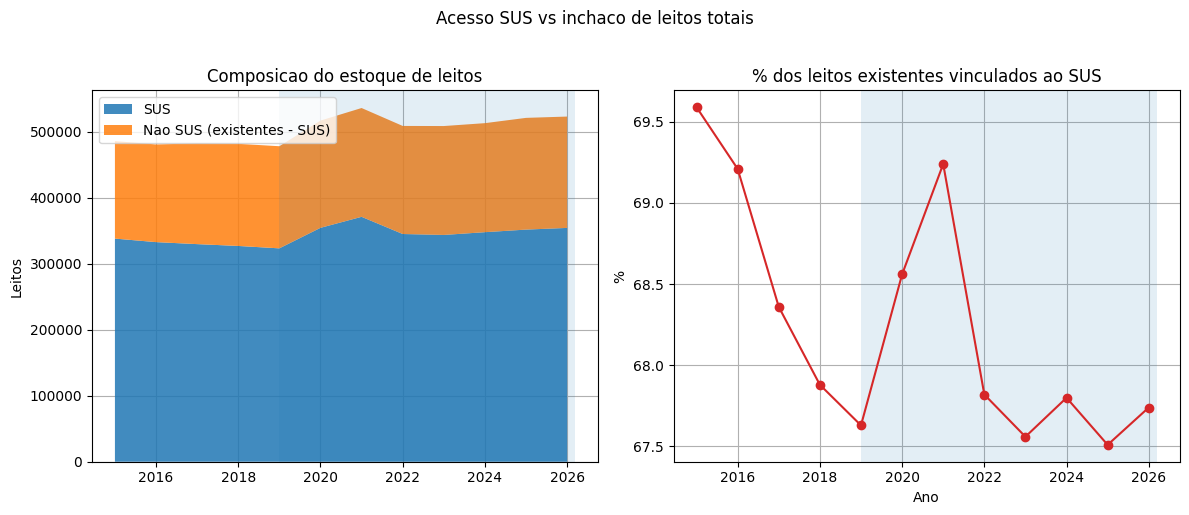


PLACAR SUS (taxa_sus):
  Bolsonaro 2019→2022: 67.63% → 67.82%  (Δ +0.19 p.p.)
  Lula 2023→2025:      67.56% → 67.51%  (Δ -0.05 p.p.)

Variacao de leitos NAO SUS:
  Bolsonaro: +9009
  Lula:      +4276

PROVOCACAO: Se existentes sobem e a taxa SUS cai, o pais "ganhou leitos" sem
necessariamente ganhar acesso. Se a taxa sobe, o periodo fortaleceu vinculo SUS
mesmo que o total nao exploda — narrativa oposta a corrida pelo numero cheio.



In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]
ax.stackplot(
    decomp["ANO_INT"],
    decomp["leitos_sus"],
    decomp["leitos_nao_sus"],
    labels=["SUS", "Nao SUS (existentes - SUS)"],
    alpha=0.85,
)
ax.axvspan(2019, 2022.5, alpha=0.12)
ax.axvspan(2022.5, 2026.2, alpha=0.12)
ax.set_title("Composicao do estoque de leitos")
ax.set_ylabel("Leitos")
ax.legend(loc="upper left")

ax = axes[1]
ax.plot(decomp["ANO_INT"], decomp["taxa_sus_pct"], marker="o", color="C3")
ax.axvspan(2019, 2022.5, alpha=0.12)
ax.axvspan(2022.5, 2026.2, alpha=0.12)
ax.set_title("% dos leitos existentes vinculados ao SUS")
ax.set_ylabel("%")
ax.set_xlabel("Ano")

fig.suptitle("Acesso SUS vs inchaco de leitos totais", y=1.02)
fig.tight_layout()
fig.savefig(FIG / "04_composicao_sus.png", dpi=140)
plt.show()

b19 = decomp.loc[decomp["ANO_INT"] == 2019].iloc[0]
b22 = decomp.loc[decomp["ANO_INT"] == 2022].iloc[0]
l23 = decomp.loc[decomp["ANO_INT"] == 2023].iloc[0]
l25 = decomp.loc[decomp["ANO_INT"] == 2025].iloc[0]

print(
    f"""
PLACAR SUS (taxa_sus):
  Bolsonaro 2019→2022: {b19['taxa_sus_pct']:.2f}% → {b22['taxa_sus_pct']:.2f}%  (Δ {b22['taxa_sus_pct']-b19['taxa_sus_pct']:+.2f} p.p.)
  Lula 2023→2025:      {l23['taxa_sus_pct']:.2f}% → {l25['taxa_sus_pct']:.2f}%  (Δ {l25['taxa_sus_pct']-l23['taxa_sus_pct']:+.2f} p.p.)

Variacao de leitos NAO SUS:
  Bolsonaro: {int(b22['leitos_nao_sus']-b19['leitos_nao_sus']):+d}
  Lula:      {int(l25['leitos_nao_sus']-l23['leitos_nao_sus']):+d}

PROVOCACAO: Se existentes sobem e a taxa SUS cai, o pais "ganhou leitos" sem
necessariamente ganhar acesso. Se a taxa sobe, o periodo fortaleceu vinculo SUS
mesmo que o total nao exploda — narrativa oposta a corrida pelo numero cheio.
"""
)


## Conclusão

1. **Placar de estoque:** 2019–2022 sobe mais que 2023–2025 em leitos SUS e existentes — com asterisco pandêmico obrigatório (UTI SUS dispara no primeiro período).
2. **Desigualdade espacial:** a fatia do centro econômico **recuou** entre 2019 e 2022; sob Lula, ficou estável. A narrativa “cresceu só para ricos” não se sustenta só com share regional neste recorte.
3. **Per capita:** SP/RJ/MG são gigantes absolutos e medianos/baixos na oferta por habitante — volume ≠ cobertura.
4. **SUS:** a taxa de vínculo SUS oscila em torno de ~67–68% nos dois governos; crescimento de estoque não foi, em si, uma revolução de acesso.

Polarização serve para abrir a conversa. Os microdados pedem nuance: pandemia, federalismo e a diferença entre **existir leito** e **existir leito SUS**.

Fontes: Dados Abertos do SUS (Hospitais e Leitos); população IBGE (data/external/populacao_uf_ibge.csv).
